# Clef Atlas: from a photograph to a decision

A walkthrough of the Python/FastAPI GeoGuessr-style demo, for a team already familiar with LLMs.

**The central distinction:** a conventional generative model produces tokens; Clef scores the options supplied in a decision schema. Both can classify a scene. What changes is the inference/output mechanism and how the application can consume uncertainty.

Run the cells in order. The notebook defaults to **no network calls** and uses clearly labelled fixtures. Live examples require your own credentials and explicit switches below. No photo dataset is bundled.

**Route through the notebook:** setup → decision schema → response → policy → photos → application flow → hierarchy → LLM comparison → evaluation.


## 1. Open this in VS Code

From the extracted project folder, create/activate the virtual environment as described in `README.md`, then:

```bash
python -m pip install -r requirements-notebook.txt
```

Install VS Code's Python and Jupyter extensions, open `clef_walkthrough.ipynb`, and select the `.venv` Python kernel. Alternatively install JupyterLab (`python -m pip install jupyterlab`) and run `jupyter lab`.

The notebook imports the actual implementation from `app/main.py`; you do not need to start Uvicorn. Put credentials in `.env`, never in notebook cells. Avoid sharing notebook outputs from real requests containing private clues or photos.


In [2]:
from pathlib import Path
import base64
import copy
import inspect
import io
import json
import os
import sys
from statistics import median
from unittest.mock import patch

# Works when the kernel starts in the project root or a child directory.
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "app" / "main.py").exists()), None)
if PROJECT is None:
    raise RuntimeError("Start the notebook kernel inside the extracted clef-geoguesser folder.")
sys.path.insert(0, str(PROJECT))
from app import main as demo
from IPython.display import display, HTML
from PIL import Image

RUN_LIVE = False      # Set True to call Workers AI (uses your account billing).
RUN_LLM = False       # Independently enables the optional OpenAI comparison.
PHOTO_PATH = None     # Example: PROJECT / "my_round.jpg"; not sent unless RUN_LIVE/RUN_LLM.

print("Project:", PROJECT.name)
print("Cloudflare credentials configured:", bool(os.getenv("CLOUDFLARE_ACCOUNT_ID")
                                                and os.getenv("CLOUDFLARE_AUTH_TOKEN")))
print("OpenAI key configured:", bool(os.getenv("OPENAI_API_KEY")))


Project: clef-geoguesser
Cloudflare credentials configured: False
OpenAI key configured: False


## 2. What is different from a conventional LLM?

Clef still uses a language-model backbone. According to Cloudflare, it processes the input with a prefill-only backbone pass and a specialised decision head that scores schema options together, instead of decoding an answer token by token. That is the architectural difference—not simply asking an LLM to respond with JSON. [Cloudflare architecture explanation](https://blog.cloudflare.com/clef-decision-models/).

| Question | Clef decision model | Conventional generative vision LLM |
|---|---|---|
| How does it answer? | Scores supplied schema options | Generates a sequence of output tokens |
| Can it classify countries? | Yes, among supplied options | Yes, with prompts and optional constrained output |
| Can it produce explanations or arbitrary coordinates? | Not as open-ended text/numbers; define choices first | Can generate them, but correctness still needs checking |
| How is uncertainty exposed here? | Probability for each candidate | Our comparator returns a country only |
| Can options change each request? | Yes; the app builds schemas dynamically | Yes; prompts/schemas can change too |
| Why might we use it? | Bounded routing decisions with a distribution to drive policy | Explanations, extraction, planning, open-ended synthesis |

**A correction to an overly simple pitch:** structured output is not exclusive to Clef. Conventional LLM APIs can constrain outputs to JSON schemas, including enums. Our first-version comparator uses JSON mode plus validation, rather than a strict enum schema. [Structured Outputs documentation](https://developers.openai.com/api/docs/guides/structured-outputs).

Neither valid structure nor a high score guarantees semantic correctness. Speed, cost and calibration on these photographs are empirical questions. Clef is not necessarily faster than every small LLM for every request.


## 3. Define the problem as a decision schema

The API separates **evidence** (`state`, optionally `images`) from **the decision contract** (`questions`). For a `choice` question, `criteria` maps stable application keys to meaningful descriptions. The keys need not have existed at development time; the app constructs them for each request.

Other supported question types are `noul` for a yes/no decision and `score` for ordered levels. This game uses `choice`. It cannot output a country that you leave out. In a production router, include an appropriate abstention option or separate review policy and evaluate it.

[Clef API reference](https://developers.cloudflare.com/workers-ai/models/clef/).


In [3]:
candidates = ["portugal", "spain", "italy", "france"]
clue = demo.SCENARIOS[0]["clue"]
criteria = {key: demo.COUNTRIES[key][0] for key in candidates}
payload = {
    "model": "clef",
    "state": clue,
    "questions": {
        "location": {
            "type": "choice",
            "instructions": "Which country is most likely, among these candidates?",
            "criteria": criteria,
        }
    },
}
print(json.dumps(payload, indent=2))


{
  "model": "clef",
  "state": "A narrow cobblestone street, yellow trams, Portuguese signs and tiled facades.",
  "questions": {
    "location": {
      "type": "choice",
      "instructions": "Which country is most likely, among these candidates?",
      "criteria": {
        "portugal": "Portugal",
        "spain": "Spain",
        "italy": "Italy",
        "france": "France"
      }
    }
  }
}


## 4. Make the call using the real application adapter

Workers AI is Cloudflare's hosted inference service. Our Mac runs the UI and Python application; Cloudflare runs the model. No GPU or Cloudflare deployment is needed for this REST approach.

`demo.clef()` sends the payload to the account-scoped `/ai/run/@cf/cloudflare/clef` endpoint, unwraps Cloudflare's `result`, and validates the returned choice and probability fields. `demo.post_json()` handles the HTTP call, timeout and provider failures. The bearer token remains in Python.

The cell below takes that same code path with a **mocked provider response** unless `RUN_LIVE=True`. The numbers are a teaching fixture based on the successful text response shared during setup, not a new measurement. In live mode, changing the question/candidate context may change the response.


In [4]:
fixture = {
    "success": True,
    "result": {
        "model": "clef",
        "answers": {
            "location": {
                "type": "choice",
                "choice": "portugal",
                "probabilities": {"portugal": 0.9827, "spain": 0.0102,
                                  "italy": 0.0038, "france": 0.0033},
                "confidence": 0.9546,
            }
        },
        "usage": {"input_tokens": 183, "output_tokens": 0},
    },
}
request = demo.Predict(model="clef", mode="live", clue=clue, candidates=candidates)

async def fixture_provider(url, token, body):
    assert body["questions"]["location"]["criteria"] == criteria
    return copy.deepcopy(fixture)

if RUN_LIVE:
    answer = await demo.clef(request, criteria, payload["questions"]["location"]["instructions"])
    print("LIVE RESPONSE")
else:
    # Dummy credentials satisfy the adapter; the HTTP function is replaced.
    with patch.dict(os.environ, {"CLOUDFLARE_ACCOUNT_ID": "fixture-account",
                                 "CLOUDFLARE_AUTH_TOKEN": "fixture-token"}), \
         patch.object(demo, "post_json", fixture_provider):
        answer = await demo.clef(request, criteria, payload["questions"]["location"]["instructions"])
    print("FIXTURE RESPONSE — no network request")
print(json.dumps(answer, indent=2))


FIXTURE RESPONSE — no network request
{
  "choice": "portugal",
  "probabilities": {
    "portugal": 0.9827,
    "spain": 0.0102,
    "italy": 0.0038,
    "france": 0.0033
  },
  "confidence": 0.9546,
  "usage": {
    "input_tokens": 183,
    "output_tokens": 0
  }
}


## 5. Interpret the response before using it

`choice` is the returned category key. `probabilities` exposes scores across the allowed options. `usage` reports billing-related tokens. The provider also returns a `confidence` field: do **not** assume that it equals the selected option's probability. In the fixture, these are 0.9546 and 0.9827 respectively.

Our app's slider uses the top country's **probability**, not the separate confidence field. It also does not prove calibration: “0.9” is useful as a routing score, but treating it as 90% expected accuracy requires testing against labels from the target domain.

A candidate distribution cannot detect every missing-country case. If a photo is from Greece but the candidates are Portugal/Spain/Italy/France, the model must still choose within that set.


In [5]:
from html import escape

def probability_bars(probabilities):
    rows = []
    for key, p in sorted(probabilities.items(), key=lambda item: item[1], reverse=True):
        label = escape(demo.COUNTRIES.get(key, (key,))[0])
        rows.append(f'<div style="display:flex;gap:12px;align-items:center;margin:8px 0">'
                    f'<span style="width:140px">{label}</span>'
                    f'<div style="width:300px;background:#ddd;border-radius:4px">'
                    f'<div style="height:12px;width:{p*100:.2f}%;background:#428b63"></div></div>'
                    f'<span>{p:.2%}</span></div>')
    display(HTML('<div style="padding:12px">' + ''.join(rows) + '</div>'))

probability_bars(answer["probabilities"])
print("Selected probability:", answer["probabilities"][answer["choice"]])
print("Separate provider confidence:", answer["confidence"])


Selected probability: 0.9827
Separate provider confidence: 0.9546


## 6. The application owns the policy

The model supplies a distribution; ordinary code decides what to do. We can change the threshold without another model call. This generalises from guessing a country to routing tickets, choosing tools or requesting human review.

The example below uses the previous response. An application that cannot tolerate certain errors also needs explicit safeguards and a domain-specific evaluation; this slider alone is only a teaching aid.


In [6]:
def routing_policy(result, threshold=0.95):
    p = result["probabilities"][result["choice"]]
    return "auto-route" if p >= threshold else "human review"

for threshold in [0.80, 0.95, 0.99]:
    print(f"Threshold {threshold:.0%}: {routing_policy(answer, threshold)}")


Threshold 80%: auto-route
Threshold 95%: auto-route
Threshold 99%: human review


## 7. Add vision: the evidence changes, the schema stays the same

A photo becomes an embedded data URL in `images`; the country question does not change. Our `clean_image()` decodes the file, applies EXIF orientation, converts to RGB, resizes and re-encodes JPEG. This strips embedded location metadata so GPS tags cannot give away the answer. It cannot remove clues visibly printed in the image.

This demo accepts PNG/JPEG/WebP below 4 MiB and up to 16 megapixels, and shrinks to a 1280-pixel bounding box. Known country/GPS values are only used at reveal time, never in model requests. Remote image URLs are not sent to Clef. [Media example](https://developers.cloudflare.com/changelog/post/2026-10-09-clef-omni-workers-ai/).

Set `PHOTO_PATH` above to a real photograph. Without one, the next cell uses a synthetic colour patch to demonstrate encoding only—it is not a geolocation example. Photos are sent to the provider only if live inference is enabled.


Synthetic image: encoding demonstration only.
Prepared image: JPEG (320, 180)
Remaining EXIF fields: 0


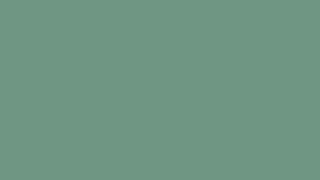

Embedded image prefix: data:image/jpeg;base64


In [7]:
if PHOTO_PATH is None:
    sample = Image.new("RGB", (320, 180), color=(110, 150, 130))
    buffer = io.BytesIO()
    sample.save(buffer, format="PNG")
    raw = buffer.getvalue()
    print("Synthetic image: encoding demonstration only.")
else:
    photo_file = Path(PHOTO_PATH).expanduser()
    if photo_file.stat().st_size > 4 * 1024 * 1024:
        raise ValueError("Choose a photo smaller than 4 MiB.")
    raw = photo_file.read_bytes()
    print("Using your photo; only visible content will be sent.")

image_data = demo.clean_image(raw)
with Image.open(io.BytesIO(base64.b64decode(image_data.split(",", 1)[1]))) as prepared:
    print("Prepared image:", prepared.format, prepared.size)
    print("Remaining EXIF fields:", len(prepared.getexif()))
    display(prepared.copy())
print("Embedded image prefix:", image_data.split(",", 1)[0])
# Do not print the entire base64 payload: it is large and contains the photo.


In [8]:
photo_answer = None
if RUN_LIVE and PHOTO_PATH is not None:
    photo_request = demo.Predict(model="clef", mode="live", clue="",
                                 image=image_data, candidates=candidates)
    demo.validate(photo_request)
    photo_answer = await demo.clef(photo_request, criteria,
                                  "Which country is most likely, among these candidates?")
    probability_bars(photo_answer["probabilities"])
else:
    print("Photo inference skipped. Set PHOTO_PATH and RUN_LIVE to run it.")


Photo inference skipped. Set PHOTO_PATH and RUN_LIVE to run it.


## 8. Trace the web application

The browser displays the game, submits evidence/candidates and renders the response. The Python server validates inputs, chooses the model adapter and returns a common response envelope. This keeps credentials out of JavaScript.

| File or endpoint | Role |
|---|---|
| `app/static/index.html` | Controls, image panel, map, results layout |
| `app/static/app.js` | Game state, requests, probability bars, threshold and export |
| `GET /api/config` | Public country metadata, practice clues, credential availability flags |
| `POST /api/image` | Decode, resize and strip image metadata |
| `POST /api/predict` | Offline fixture / Clef / optional LLM routing |
| `POST /api/reveal` | Reveal bundled round answer and score the human guess |
| `app/main.py:clef` / `llm` | Provider-specific request and response adaptation |

Custom-photo truth is held by the browser for reveal. Practice-round labels stay on the server until reveal, although they remain discoverable by someone inspecting the source/API; this is a presentation game, not a secure competition.

Run the same prediction function directly below. Its offline branch is an invented fixture; it does not call Clef or execute the hierarchy. No running web server is required.


In [9]:
offline_result = await demo.predict(demo.Predict(
    model="clef", mode="offline", clue=clue, candidates=candidates))
print(json.dumps(offline_result, indent=2))
print("Human distance example (km):", demo.distance(38.72, -9.14, 40.42, -3.70))


{
  "model": "clef",
  "strategy": "direct",
  "mode": "offline",
  "choice": "portugal",
  "probabilities": {
    "portugal": 0.82,
    "spain": 0.06000000000000002,
    "italy": 0.06000000000000002,
    "france": 0.06000000000000002
  },
  "stages": [
    {
      "stage": "Illustrative fixture",
      "choice": "portugal",
      "probabilities": {
        "portugal": 0.82,
        "spain": 0.06000000000000002,
        "italy": 0.06000000000000002,
        "france": 0.06000000000000002
      },
      "confidence": null,
      "usage": {}
    }
  ],
  "latency_ms": null,
  "input_tokens": 0,
  "estimated_cost_usd": null,
  "note": "Illustrative fixture; no API call or measured performance."
}
Human distance example (km): 503


## 9. Dynamic schemas and greedy hierarchy

Hierarchy is implemented in **our application**, not by a special geographic Clef API. `predict()` derives continents from the current candidate set, asks Clef, filters candidates, then repeats for regions and countries. It skips single-option levels.

This demonstrates dynamic schemas, but an ordinary LLM can also be placed in a hierarchy. The Clef-specific feature is the decision output consumed at each step.

Watch the actual implementation with a deterministic mocked provider. We include Portugal, Spain and Japan. Europe wins, only Southern Europe remains, so the app skips the region call and asks Portugal vs Spain. Mocking lets us inspect the requests without confusing the app's offline fixtures with a real hierarchy run.


In [10]:
hierarchy_requests = []
async def hierarchy_provider(url, token, body):
    options = body["questions"]["location"]["criteria"]
    hierarchy_requests.append(copy.deepcopy(body))
    if "Europe" in options:
        choice, scores = "Europe", {"Europe": 0.6, "Asia": 0.4}
    else:
        choice, scores = "portugal", {"portugal": 0.7, "spain": 0.3}
    return {"success": True, "result": {
        "answers": {"location": {"choice": choice, "probabilities": scores}},
        "usage": {"input_tokens": 100, "output_tokens": 0}}}

with patch.dict(os.environ, {"CLOUDFLARE_ACCOUNT_ID": "fixture-account",
                             "CLOUDFLARE_AUTH_TOKEN": "fixture-token"}), \
     patch.object(demo, "post_json", hierarchy_provider):
    hierarchy = await demo.predict(demo.Predict(
        mode="live", strategy="hierarchical", clue=clue,
        candidates=["portugal", "spain", "japan"]))

for i, body in enumerate(hierarchy_requests, 1):
    print(f"Mock call {i}:", body["questions"]["location"]["criteria"])
print("Stages:", [s["stage"] for s in hierarchy["stages"]])
print("Returned country probabilities:", hierarchy["probabilities"])
print("Timing/cost above are mocked-path artefacts, NOT provider measurements.")


Mock call 1: {'Europe': 'Europe', 'Asia': 'Asia'}
Mock call 2: {'portugal': 'Portugal', 'spain': 'Spain'}
Stages: ['Continent', 'Country']
Returned country probabilities: {'portugal': 0.7, 'spain': 0.3}
Timing/cost above are mocked-path artefacts, NOT provider measurements.


### Conditional probabilities and the 100% trap

The hierarchy returned Portugal at 70% **within the Europe branch**. It did not return Portugal at 70% over the original country set. If these were consistent conditional probabilities, a tree estimate for the path would be 0.6 × 0.7 = 0.42. The app currently returns the final conditional distribution, not that estimate.

Even multiplying scores does not establish calibrated geographic probabilities across separately prompted calls. A fuller tree would need alternative branches, their child distributions, and evaluation. A greedy tree also cannot recover from an incorrect continent choice.

An especially revealing case: selecting Asia leaves just Japan in this example. The app returns `{japan: 1.0}` without another model call. That is certainty about the **remaining option set**, not proof that the photo is Japanese. Applying the slider directly to this forced output is misleading. A production policy would consider path uncertainty and explicit abstention.


In [11]:
print("Illustrative path estimate:", 0.6 * 0.7)
remaining_after_asia = [k for k in ["portugal", "spain", "japan"]
                        if demo.COUNTRIES[k][1] == "Asia"]
print("Countries left after choosing Asia:", remaining_after_asia)
print("Forced leaf distribution:", {remaining_after_asia[0]: 1.0})


Illustrative path estimate: 0.42
Countries left after choosing Asia: ['japan']
Forced leaf distribution: {'japan': 1.0}


## 10. Compare the conventional vision LLM fairly

`llm()` sends the same evidence and candidate countries, asks for a JSON object, then parses the generated message and validates membership. It returns no probability distribution. A prose “confidence” from an LLM would not be comparable to a schema-option probability without validation; token log probabilities are also not automatically country probabilities.

This baseline deliberately asks for a short classification, not a long explanation. It uses JSON mode, so malformed/missing country fields are handled by validation. A stronger comparison would add a strict country-enum schema, use equivalent image preprocessing, fix model versions where possible, and repeat requests. The task itself is achievable by either model.

Below is the exact adapter, so the walkthrough stays grounded in the shipped code. The optional call uses `OPENAI_MODEL` from `.env` and your account billing. Text is used unless a real photo was selected; photo truth never enters this request.


In [12]:
print(inspect.getsource(demo.llm))


async def llm(req):
    token=os.getenv('OPENAI_API_KEY','')
    if not token: raise HTTPException(400,'Set OPENAI_API_KEY in .env and restart to enable the comparison.')
    prompt='Choose the most likely country from these candidates: '+json.dumps({k:COUNTRIES[k][0] for k in req.candidates})+'. Return JSON with a single country key. No explanations. Clues: '+req.clue
    content=[{'type':'text','text':prompt}]
    if req.image: content.append({'type':'image_url','image_url':{'url':req.image}})
    data=await post_json('https://api.openai.com/v1/chat/completions',token,{'model':os.getenv('OPENAI_MODEL','gpt-4o-mini'),'messages':[{'role':'user','content':content}], 'response_format':{'type':'json_object'},'max_tokens':100})
    try:
        choice=json.loads(data['choices'][0]['message']['content'])['country']
        if choice not in req.candidates: raise ValueError()
        return {'choice':choice,'probabilities':None,'confidence':None,'usage':data.get('usage',{})}
    except (KeyEr

In [13]:
llm_answer = None
if RUN_LLM:
    llm_request = demo.Predict(
        model="llm", mode="live", candidates=candidates,
        clue="" if PHOTO_PATH is not None else clue,
        image=image_data if PHOTO_PATH is not None else None,
    )
    demo.validate(llm_request)
    llm_answer = await demo.llm(llm_request)
    print(json.dumps(llm_answer, indent=2))
else:
    print("LLM call skipped. Set RUN_LLM=True to enable it.")


LLM call skipped. Set RUN_LLM=True to enable it.


## 11. What should we actually measure?

Use labelled photographs withheld from prompt design. Compare country accuracy, top-k ranking where available, candidate coverage, end-to-end median/p95 latency, token usage and billed cost. Separate direct and hierarchical runs, text and image inputs, model versions and candidate sets. Repeat runs and record failures rather than discarding them. Human distance uses an actual map guess; the app's AI pins are representative capital locations, not inferred GPS coordinates.

For a routing threshold, track **coverage** (fraction automated) and **error rate among automated decisions**. Measure calibration by comparing predicted scores with correctness on many held-out examples. Threshold selection on the same examples used to report performance gives an optimistic result.

The following invented dataset only illustrates the trade-off. It is independent of Clef and intentionally contains a confidently wrong answer.


In [14]:
labelled_fixture = [
    {"p": .99, "correct": True},
    {"p": .97, "correct": False},
    {"p": .91, "correct": True},
    {"p": .84, "correct": True},
    {"p": .72, "correct": False},
    {"p": .55, "correct": True},
]
print("ILLUSTRATIVE data only")
for threshold in [.5, .8, .95, .99, 1.0]:
    selected = [r for r in labelled_fixture if r["p"] >= threshold]
    coverage = len(selected) / len(labelled_fixture)
    error = sum(not r["correct"] for r in selected) / len(selected) if selected else None
    error_text = f"{error:.1%}" if error is not None else "undefined (no automation)"
    print(f"Threshold {threshold:.0%}: coverage={coverage:.1%}; automated error={error_text}")


ILLUSTRATIVE data only
Threshold 50%: coverage=100.0%; automated error=33.3%
Threshold 80%: coverage=66.7%; automated error=25.0%
Threshold 95%: coverage=33.3%; automated error=50.0%
Threshold 99%: coverage=16.7%; automated error=0.0%
Threshold 100%: coverage=0.0%; automated error=undefined (no automation)


### Inspect a real exported session (optional)

The web UI can export predictions, stages and usage. It does not export a labelled evaluation dataset: correctness is shown at reveal but not stored with each prediction. Therefore exports alone support timing/usage analysis, not accuracy or calibration. Join them to separately recorded ground truth using stable round IDs for practice; custom photos currently share the generic ID `custom photo`, so add unique IDs before benchmarking many photos.

This cell reports only genuinely live entries; offline fixtures are excluded. Mocked examples in this notebook are not web exports.


In [15]:
SESSION_PATH = None  # Example: PROJECT / "clef-atlas-session.json"
if SESSION_PATH is not None:
    session = json.loads(Path(SESSION_PATH).read_text())
    groups = {}
    for result in session.get("results", []):
        if result.get("mode") == "live" and result.get("latency_ms") is not None:
            groups.setdefault((result["model"], result["strategy"]), []).append(result)
    for group, rows in groups.items():
        times = sorted(r["latency_ms"] for r in rows)
        print(group, "n=", len(rows), "median_ms=", median(times))
else:
    print("Session analysis skipped; export from the UI and set SESSION_PATH.")


Session analysis skipped; export from the UI and set SESSION_PATH.


## 12. Where this pattern fits at work

| Demo concept | Transfer to work |
|---|---|
| Candidate countries | Currently available tools, owner teams, policy outcomes |
| Image/clue evidence | Ticket text, tool state, screenshots or documents |
| Per-candidate probability | Ranking and a signal for review policy |
| Dynamic hierarchy | Routing across services, then choosing a specialised tool |
| Conventional LLM comparator | Decide where generation or deeper analysis is worth its cost |
| Labelled photo evaluation | Domain-specific decision-quality and calibration testing |

A practical experiment: find a high-volume LLM call that only returns an enum. Define its candidate contract, collect labels, compare Clef with your existing implementation, and choose the application policy from measured error costs. Keep an LLM when you need an explanation, synthesis or an output outside the candidate space.

**For the team presentation:** show the request schema, reveal the distribution, move the threshold without another inference call, demonstrate a wrong hierarchy branch, then discuss which enum-returning calls in your own systems could use this pattern.

## References and implementation limits

- [Clef announcement and architecture](https://blog.cloudflare.com/clef-decision-models/)
- [Clef API reference](https://developers.cloudflare.com/workers-ai/models/clef/)
- [Cloudflare REST setup](https://developers.cloudflare.com/workers-ai/get-started/rest-api/)
- [Multimodal input example and pricing update](https://developers.cloudflare.com/changelog/post/2026-10-09-clef-omni-workers-ai/)
- [Conventional LLM Structured Outputs](https://developers.openai.com/api/docs/guides/structured-outputs)

Sources checked 12 October 2026. The notebook does not establish a speed/accuracy winner. It runs the existing demo implementation, whose offline branch is illustrative, hierarchy is greedy, country shortlist is limited, and LLM cost is not estimated. Actual calls require your own keys. No live inference was executed when preparing this notebook.
